<center><h1>Decay Rates</h1></center>
<hr/>

Assigns decay rates to PSS network species by biological type:

| Type | Source |
|---|---|
| **mRNA / ncRNA / miRNA** | Median from `ath_decay_rates.tsv` (all species) |
| **Protein / Protein active** | 0.08/0.2/0.02 day⁻¹ → `2.31e-7 s⁻¹` |
| **Metabolite** (product-only) | Placeholder (`0.01`) — *TODO* |
| Abiotic, Complex, Gene, Process | Not needed → `None` |

In [1]:
import re
from pathlib import Path

import dill
import pandas as pd

from scripts.utils import (
    ATH_DECAY_RATES,
    PSS_DECAY_RATE_MAPPER,
    PSS_REACTIONS_PATH,
    PSS_SPECIES_PATH,
    RED, RESET,
    plt, sns,
)

## Load

In [2]:
import json

reactions = json.loads(Path(PSS_REACTIONS_PATH).read_text())
species   = json.loads(Path(PSS_SPECIES_PATH).read_text())

print(f"Loaded {len(species)} species and {len(reactions)} reactions.")

Loaded 1139 species and 864 reactions.


## Compute average mRNA / ncRNA / miRNA decay rate

> **TODO**: decide whether to use the overall file median (Option 1) or only species present in the PSS (Option 2).

In [3]:
decay_file = pd.read_csv(ATH_DECAY_RATES, sep='\t')

# Option 1 — median over all ~12k loci in the file
avg_rna_decay = decay_file['decay'].median()

# Option 2 — median over loci that appear in the PSS
pss_gene_names  = [species[s]['name'] for s in species if species[s]['type'] in ('mirna', 'mrna', 'ncrna')]
pss_loci        = set(re.findall(r'AT\dG\d{5}', ','.join(pss_gene_names)))
avg_rna_decay2  = decay_file[decay_file['locus'].isin(pss_loci)]['decay'].median()

print(f"Option 1 (all)      → {avg_rna_decay}")
print(f"Option 2 (PSS only) → {avg_rna_decay2}")

decay_file  # preview

Option 1 (all)      → 0.18395467053696204
Option 2 (PSS only) → nan


,locus,decay
0,AT1G64100,0.890730
1,AT3G60630,0.774132
2,AT1G27370,0.755072
3,AT5G37020,0.285864
4,AT5G07680,0.264384
...,...,...
12547,AT2G29500,0.009982
12548,AT1G09740,0.009397
12549,AT5G12020,0.007349
12550,AT4G19830,0.007276


For option 2, we can see that no species in the given file are matched with our PSS species, thus we opt for option 1.

## Identify degraded species

Only species that are **products but never substrates** in any reaction need explicit degradation reactions.

In [4]:
all_substrates = {s for r in reactions.values() for s in r['reactants']}
all_products   = {s for r in reactions.values() for s in r['products']}

terminal_metabolites = [
    s for s in all_products
    if species[s]['type'] == 'metabolite'
]
terminal_proteins = [
    s for s in all_products
    if species[s]['type'] in ('protein', 'protein_active')
]

print(f"{len(terminal_metabolites)} terminal metabolites, {len(terminal_proteins)} terminal proteins.")

135 terminal metabolites, 293 terminal proteins.


## Build decay-rate mapper

In [5]:
PROTEIN_DECAY    = 2.31e-7          # s⁻¹
METABOLITE_DECAY = 0.01            # TODO: confirm appropriate value
RNA_DECAY        = avg_rna_decay    # Option 1 (all-file median)


def decay_rate(specie: str):
    """Return the decay rate for *specie*, or None if no degradation is needed."""
    stype = species[specie]['type']
    if stype in ('protein', 'protein_active') and specie in terminal_proteins:
        return PROTEIN_DECAY
    if stype in ('mrna', 'ncrna', 'mirna'):
        return RNA_DECAY
    if stype == 'metabolite' and specie in terminal_metabolites:
        return METABOLITE_DECAY
    return None

### Example usage

In [6]:
# Show decay rates for every participant in the first reaction
first_rxn_id   = next(iter(reactions))
first_rxn_info = reactions[first_rxn_id]
print(f"Reaction: {first_rxn_id}")
print(first_rxn_info)

for entity in (s for vals in first_rxn_info.values() for s in vals):
    rate = decay_rate(entity)
    if rate:
        print(f"  {RED}{entity}{RESET} → decay = {rate}")
    else:
        print(f"  {entity} → no degradation")

Reaction: rx00669
{'reactants': ['s_VPg_cyt_p', 's_LHB1B1_cyt_p'], 'products': ['s_LHB1B1VPg_cyt_c'], 'modifiers': []}
  s_VPg_cyt_p → decay = 2.31e-07
  s_LHB1B1_cyt_p → no degradation
  s_LHB1B1VPg_cyt_c → no degradation


## Visualise decay-rate distribution

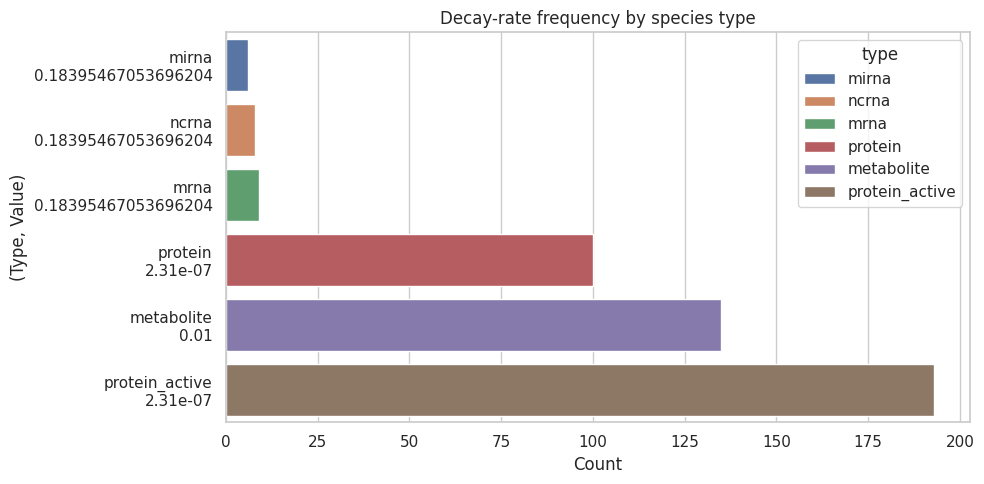

In [7]:
all_species = set(sum([sum(reactions[reaction].values(), []) for reaction in reactions], []))

rows = [
    (decay_rate(s), species[s]['type'])
    for s in all_species
]
df = pd.DataFrame(rows, columns=['value', 'type'])

counts = (
    df.value_counts(subset=['value', 'type'])
      .reset_index(name='count')
)
counts['label'] = counts['type'] + '\n' + counts['value'].astype(str)
counts = counts.sort_values('count')

plt.figure(figsize=(10, 5))
sns.barplot(data=counts, x='count', y='label', hue='type', dodge=False)
plt.xlabel("Count")
plt.ylabel("(Type, Value)")
plt.title("Decay-rate frequency by species type")
plt.tight_layout()
plt.show()

## Save

In [8]:
# with open(PSS_DECAY_RATE_MAPPER, 'wb') as f:
#     dill.dump(decay_rate, f)

# print(f"Saved decay-rate mapper → {PSS_DECAY_RATE_MAPPER}")

In [9]:
import numpy as np
np.unique([str(decay_rate(specie)) for specie in species], return_counts = True)

(array(['0.01', '0.18395467053696204', '2.31e-07', 'None'], dtype='<U19'),
 array([135,  23, 293, 688]))